# BusBooking - Kaggle CPU Load Testing (Pha 1)

**Mục tiêu:** chạy Spring Boot Java 21, PostgreSQL và Locust **trong cùng một Kaggle CPU notebook**, không cần Docker. Thu thập RPS, latency p50/p95/p99, error rate và CPU/RAM để bàn giao nhóm Pha 2.

**Trước khi chạy:**
1. Trên Windows: `./mvnw.cmd -DskipTests clean package` (PowerShell dùng `./` hoặc `.\mvnw.cmd`). Chọn file JAR thực thi Spring Boot ở `target/` (không chọn `.jar.original`).
2. Tạo một **Kaggle Dataset riêng tư (Private)** chứa JAR đó. Trong Kaggle Notebook, chọn **Add Input** để gắn Dataset.
3. Nếu đã có dữ liệu **hoàn toàn giả lập** trong local dev, có thể tạo một `seed.sql` riêng (hướng dẫn ở cuối notebook) rồi gắn làm Private Dataset thứ hai. **Không upload DB người dùng thật, mật khẩu, token, OTP, `.env` hoặc file backup chứa bí mật.**
4. Tạo Kaggle Notebook mới → **Accelerator = None (CPU)**, **Internet = On** để cài Java/PostgreSQL/Locust.
5. Import notebook này hoặc sao chép các cell, chạy từ trên xuống.

**Cảnh báo:** Đây là database Kaggle độc lập; quá trình khởi động Spring Boot có chạy Flyway trên **database Kaggle**. Tuyệt đối không trỏ notebook đến PostgreSQL ở máy Windows hay môi trường production.

In [1]:
import os, sys, platform, subprocess, shutil, time, json, hashlib, pathlib, secrets, base64, socket
from pathlib import Path
WORK = Path('/kaggle/working') if Path('/kaggle/working').exists() else Path.cwd()
OUTPUT = WORK / 'busbooking_baseline'
OUTPUT.mkdir(parents=True, exist_ok=True)
print('Working directory:', WORK)
print('OS:', platform.platform())
print('Python:', sys.version.split()[0])
print('CPU logical:', os.cpu_count())
print('Kaggle CPU information:')
subprocess.run(['bash','-lc','lscpu | grep -E "Model name|CPU\(s\)|Architecture" | head -6'], check=False)

Working directory: /kaggle/working
OS: Linux-6.18.55+-x86_64-with-glibc2.39
Python: 3.13.15
CPU logical: 4
Kaggle CPU information:
Architecture:                            x86_64
CPU(s):                                  4
On-line CPU(s) list:                     0-3
Model name:                              Intel(R) Xeon(R) CPU @ 2.20GHz
NUMA node0 CPU(s):                       0-3


<>:11: SyntaxWarning: invalid escape sequence '\('
<>:11: SyntaxWarning: invalid escape sequence '\('
/tmp/ipykernel_17/216303309.py:11: SyntaxWarning: invalid escape sequence '\('
  subprocess.run(['bash','-lc','lscpu | grep -E "Model name|CPU\(s\)|Architecture" | head -6'], check=False)


CompletedProcess(args=['bash', '-lc', 'lscpu | grep -E "Model name|CPU\\(s\\)|Architecture" | head -6'], returncode=0)

## 1. Cài các công cụ tạo tải và đo tài nguyên

Cần **Internet = On** trong Settings của Kaggle. Phiên Kaggle có thể thay đổi thư viện theo thời gian; phiên bản chạy thực tế được ghi lại ở cuối.

In [2]:
subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'locust>=2.30,<3', 'psutil>=6,<9', 'requests>=2.31,<3', 'pandas>=2,<3'], check=True)
import requests, psutil, pandas as pd
print('Locust:', subprocess.check_output([sys.executable,'-m','locust','--version'], text=True).strip())
print('psutil:', psutil.__version__)

Locust: locust 2.47.0 from /usr/local/lib/python3.13/dist-packages/locust (Python 3.13.15)
psutil: 5.9.5


## 2. Chuẩn bị Java 21

Nếu hệ thống không có sẵn Java 21, tải bản JDK 21 cho Linux x64 từ Amazon Corretto. Máy Kaggle cần internet; các file tải về được lưu ở `/tmp` để tránh làm đầy Output.

In [3]:
JAVA_DIR = Path('/tmp/busbooking_jdk21')
JAVA_BIN = JAVA_DIR / 'bin/java'
if not JAVA_BIN.exists():
    archive = Path('/tmp/busbooking_java21.tar.gz')
    url = 'https://corretto.aws/downloads/latest/amazon-corretto-21-x64-linux-jdk.tar.gz'
    subprocess.run(['curl','-fL','--retry','3','-o',str(archive),url],check=True)
    extract_dir = Path('/tmp/busbooking_jdk21_extract')
    extract_dir.mkdir(exist_ok=True)
    subprocess.run(['tar','-xzf',str(archive),'-C',str(extract_dir)],check=True)
    candidate = next(p for p in extract_dir.iterdir() if (p / 'bin/java').exists())
    shutil.move(str(candidate), str(JAVA_DIR))
    archive.unlink(missing_ok=True)
assert JAVA_BIN.exists(), 'Chưa tìm được Java 21'
print(subprocess.run([str(JAVA_BIN),'-version'],capture_output=True,text=True,check=True).stderr)

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
  0     0    0     0    0     0      0      0 --:--:-- --:--:-- --:--:--     0
100  199M  100  199M    0     0   206M      0 --:--:-- --:--:-- --:--:--  242M


openjdk version "21.0.13" 2026-10-20 LTS
OpenJDK Runtime Environment Corretto-21.0.13.0.11 (build 21.0.13+11-LTS)
OpenJDK 64-Bit Server VM Corretto-21.0.13.0.11 (build 21.0.13+11-LTS, mixed mode, sharing)



## 3. Khởi động PostgreSQL riêng trong Kaggle

Chỉ thao tác với PostgreSQL **trong notebook**. Nếu gói PostgreSQL chưa tồn tại, cài bằng `apt`. Database `busbooking_kaggle` được tạo riêng; mật khẩu ngẫu nhiên giữ trong RAM notebook, không ghi vào báo cáo.

In [4]:
if shutil.which('pg_lsclusters') is None:
    print('Installing PostgreSQL (có thể tốn một ít thời gian)...')
    subprocess.run(['bash','-lc','apt-get update -qq && DEBIAN_FRONTEND=noninteractive apt-get install -y -qq postgresql postgresql-client'],check=True)
clusters=subprocess.check_output(['pg_lsclusters','--no-header'],text=True).strip().splitlines()
if not clusters:
    raise RuntimeError('PostgreSQL không có cluster; kiểm tra đầu ra apt hoặc tạo cluster bằng pg_createcluster.')
print('Clusters:', clusters)
version, cluster_name, port, status = clusters[0].split()[:4]
if status != 'online':
    subprocess.run(['pg_ctlcluster',version,cluster_name,'start'],check=True)
subprocess.run(['pg_isready','-h','127.0.0.1','-p',port],check=True)
DB_NAME='busbooking_kaggle'
DB_USER='busbooking_kaggle_user'
DB_PASSWORD=secrets.token_urlsafe(30)
def admin_sql(sql):
    return subprocess.run(['runuser','-u','postgres','--','psql','-v','ON_ERROR_STOP=1','-q'],input=sql,text=True,capture_output=True,check=True)
role_exists=subprocess.check_output(['runuser','-u','postgres','--','psql','-tAc',f"SELECT 1 FROM pg_roles WHERE rolname='{DB_USER}'"],text=True).strip()=='1'
if role_exists:
    admin_sql(f"ALTER ROLE {DB_USER} WITH LOGIN PASSWORD '{DB_PASSWORD}';")
else:
    admin_sql(f"CREATE ROLE {DB_USER} WITH LOGIN PASSWORD '{DB_PASSWORD}';")
db_exists=subprocess.check_output(['runuser','-u','postgres','--','psql','-tAc',f"SELECT 1 FROM pg_database WHERE datname='{DB_NAME}'"],text=True).strip()=='1'
if not db_exists:
    subprocess.run(['runuser','-u','postgres','--','createdb','-O',DB_USER,DB_NAME],check=True)
print('Database ready:',DB_NAME,'at localhost:'+port,'(credentials omitted)')
print('PostgreSQL:',subprocess.check_output(['psql','--version'],text=True).strip())

Installing PostgreSQL (có thể tốn một ít thời gian)...


W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)


Preconfiguring packages ...
Selecting previously unselected package libjson-perl.
(Reading database ... 125653 files and directories currently installed.)
Preparing to unpack .../00-libjson-perl_4.10000-1_all.deb ...
Unpacking libjson-perl (4.10000-1) ...
Selecting previously unselected package postgresql-client-common.
Preparing to unpack .../01-postgresql-client-common_257build1.1_all.deb ...
Unpacking postgresql-client-common (257build1.1) ...
Selecting previously unselected package ssl-cert.
Preparing to unpack .../02-ssl-cert_1.1.2ubuntu1_all.deb ...
Unpacking ssl-cert (1.1.2ubuntu1) ...
Selecting previously unselected package postgresql-common.
Preparing to unpack .../03-postgresql-common_257build1.1_all.deb ...
Adding 'diversion of /usr/bin/pg_config to /usr/bin/pg_config.libpq-dev by postgresql-common'
Unpacking postgresql-common (257build1.1) ...
Selecting previously unselected package logrotate.
Preparing to unpack .../04-logrotate_3.21.0-2build1_amd64.deb ...
Unpacking logro

## 4. Chọn Spring Boot JAR

Tự động tìm JAR trong **Add Input**. Nếu notebook có nhiều JAR, sửa `JAR_OVERRIDE` trỏ đúng file. **Không sử dụng JAR không rõ nguồn gốc.**

In [5]:
JAR_OVERRIDE = ''  # Ví dụ: '/kaggle/input/busbooking-jar/busbooking-0.0.1-SNAPSHOT.jar'
jar_candidates = sorted([p for p in Path('/kaggle/input').rglob('*.jar') if not p.name.endswith(('.jar.original','-sources.jar','-javadoc.jar'))]) if Path('/kaggle/input').exists() else []
print('JAR candidates:', *map(str,jar_candidates),sep='\n - ')
if JAR_OVERRIDE:
    JAR_PATH=Path(JAR_OVERRIDE)
elif len(jar_candidates)==1:
    JAR_PATH=jar_candidates[0]
else:
    raise RuntimeError('Gắn Kaggle Dataset chứa duy nhất Spring Boot JAR hoặc chỉnh JAR_OVERRIDE.')
assert JAR_PATH.is_file()
import zipfile
with zipfile.ZipFile(JAR_PATH) as z:
    assert any(n.startswith('BOOT-INF/') for n in z.namelist()), 'JAR này không phải Spring Boot executable JAR; hãy dùng Maven package.'
sha256 = hashlib.sha256(JAR_PATH.read_bytes()).hexdigest()
print('Selected JAR:', JAR_PATH.name)
print('SHA256:', sha256)

JAR candidates:
 - /kaggle/input/datasets/conghuybui/busbooking-jar-file/busbooking-0.0.1-SNAPSHOT.jar
Selected JAR: busbooking-0.0.1-SNAPSHOT.jar
SHA256: 64da53747b23a455d370e9385d333f16a59dc49bb17944bda664f5e249e734ee


## 5. Khởi động BusBooking

App chạy ở **127.0.0.1:8085** và dùng database Kaggle. Dùng `SPRING_DATASOURCE_*` và `DB_*` để tương thích các cách cấu hình thường gặp trong project. Cấu hình OAuth/OTP khác của dự án nếu yêu cầu có thể cần bổ sung, đọc log khởi động khi lỗi.

`BOOTSTRAP_SUPER_ADMIN_ENABLED=false` vì benchmark GET công khai chưa cần auth. Khi chạy benchmark POST sau này, phải tạo tài khoản test hợp lệ trong Kaggle.

In [6]:
API_BASE='http://127.0.0.1:8085'
app_env=os.environ.copy()
app_env.update({
  'SPRING_PROFILES_ACTIVE':'dev',
  'SERVER_PORT':'8085',
  'SPRING_DATASOURCE_URL':f'jdbc:postgresql://127.0.0.1:{port}/{DB_NAME}',
  'SPRING_DATASOURCE_USERNAME':DB_USER,
  'SPRING_DATASOURCE_PASSWORD':DB_PASSWORD,
  'DB_URL':f'jdbc:postgresql://127.0.0.1:{port}/{DB_NAME}',
  'DB_USERNAME':DB_USER,
  'DB_PASSWORD':DB_PASSWORD,
  'SPRING_FLYWAY_ENABLED':'true',
  'SPRING_JPA_HIBERNATE_DDL_AUTO':'validate',
  'JWT_SECRET':base64.b64encode(secrets.token_bytes(48)).decode(),
  'EMAIL_OTP_SECRET':base64.b64encode(secrets.token_bytes(48)).decode(),
  'BOOTSTRAP_SUPER_ADMIN_ENABLED':'false',
  'SMTP_HOST':'127.0.0.1',
  'SMTP_PORT':'1025',
  'SPRING_MAIL_HOST':'127.0.0.1',
  'SPRING_MAIL_PORT':'1025',
})
backend_log=OUTPUT/'backend.log'
if 'backend_proc' in globals() and backend_proc.poll() is None:
    print('Backend đang chạy, PID=',backend_proc.pid)
else:
    handle=open(backend_log,'w',encoding='utf-8')
    backend_proc=subprocess.Popen([str(JAVA_BIN),'-Xms256m','-Xmx1024m','-Duser.timezone=UTC','-jar',str(JAR_PATH)],
                                  env=app_env,cwd=str(WORK),stdout=handle,stderr=subprocess.STDOUT,start_new_session=True)
    handle.close()
    print('Starting Java backend, PID=',backend_proc.pid)
    deadline=time.monotonic()+150
    while time.monotonic()<deadline:
        if backend_proc.poll() is not None:
            break
        try:
            r=requests.get(API_BASE+'/api/trips',timeout=2)
            if r.status_code in (200,400,401,403,404):
                print('Backend responded:',r.status_code)
                break
        except requests.RequestException:
            pass
        time.sleep(2)
    else:
        print('Backend did not respond before timeout.')
    if backend_proc.poll() is not None:
        print('Backend process exit code:',backend_proc.returncode)
    if backend_proc.poll() is not None or not (requests.get(API_BASE+'/api/trips',timeout=3).status_code in (200,400,401,403,404)):
        print('Last 60 log lines:')
        print('\n'.join(backend_log.read_text(errors='replace').splitlines()[-60:]))
        raise RuntimeError('Backend chưa start đúng. Kiểm tra profile/env/Flyway trong log ở trên.')

Starting Java backend, PID= 2898
Backend responded: 200


## 6. Đưa dữ liệu giả lập vào database Kaggle

**Nếu database vừa tạo còn rỗng, GET `/api/trips` chỉ đọc danh sách rỗng → số liệu RPS không đại diện cho hệ thống thật.** nên tạo dataset gồm nhiều Location, Operator, Vehicle, Route và Trip trước khi benchmark.

Cách đơn giản nếu máy local đã có **dữ liệu hoàn toàn giả lập**: dùng `pg_dump --data-only --column-inserts` cho đúng 5 bảng **locations, bus_operators, vehicles, routes, trips**, đưa SQL vào **Private Kaggle Dataset**. Lưu ý `trips` có thể có FK khác; nếu restore báo thiếu FK, cần xuất thêm fixture giả lập tương ứng, **không xuất dữ liệu user thật**. Không xuất bảng `users`, `email_verifications` hoặc mật khẩu.

Nếu fixture Trip từng có Booking nhưng không xuất Booking, số ghế còn lại có thể lệch: chỉ dùng fixture đó cho GET, không dùng cho phép đo POST Booking.

Ở cell dưới, đặt `SEED_SQL_PATH` trỏ tới file bạn đã Add Input. Chỉ import **một lần** vào database mới; import lại có thể trùng ID.

In [7]:
from pathlib import Path

sql_files = list(Path("/kaggle/input").rglob("*.sql"))

for file in sql_files:
    print(file)

/kaggle/input/datasets/conghuybui/seed-sql/busbooking_seed.sql


In [8]:
SEED_SQL_PATH = "/kaggle/input/datasets/conghuybui/seed-sql/busbooking_seed.sql"  # Ví dụ: '/kaggle/input/busbooking-fixture/seed.sql'
if SEED_SQL_PATH:
    if not Path(SEED_SQL_PATH).is_file():
        raise FileNotFoundError(SEED_SQL_PATH)
    pg_env=os.environ.copy()
    pg_env['PGPASSWORD']=DB_PASSWORD
    subprocess.run(['psql','-h','127.0.0.1','-p',port,'-U',DB_USER,'-d',DB_NAME,
                    '-v','ON_ERROR_STOP=1','-f',SEED_SQL_PATH],env=pg_env,check=True)
    print('Imported synthetic fixture:',SEED_SQL_PATH)
else:
    print('Chưa chỉ định seed.sql. Nếu API trả danh sách rỗng, không chạy load test vội.')
r=requests.get(API_BASE+'/api/trips',timeout=10)
print('GET /api/trips:',r.status_code)
print('Response preview:',r.text[:1000])
assert r.status_code==200, 'GET /api/trips phải trả 200 để chạy benchmark đọc.'

def unwrap_items(obj):
    if isinstance(obj,list): return obj
    if isinstance(obj,dict):
        for k in ('content','data','trips','items','results'):
            if k in obj:
                answer=unwrap_items(obj[k])
                if isinstance(answer,list): return answer
    return None
items=unwrap_items(r.json())
if items is None:
    raise RuntimeError('Không nhận diện được dạng JSON danh sách Trip. Điều chỉnh unwrap_items theo response thực tế.')
print('Trip entries in current response:',len(items))
if not items:
    print('CẦN SEED: database chưa có Trip; kết quả benchmark GET danh sách rỗng sẽ gây hiểu nhầm.')
TRIP_ID = items[0].get('id',items[0].get('tripId')) if items and isinstance(items[0],dict) else None
print('Suggested TRIP_ID:',TRIP_ID)
if TRIP_ID is not None:
    detail=requests.get(f'{API_BASE}/api/trips/{TRIP_ID}',timeout=10)
    print('GET detail:',detail.status_code)

SET
SET
SET
SET
SET
 set_config 
------------
 
(1 row)

SET
SET
SET
SET
INSERT 0 1
INSERT 0 1
INSERT 0 1
INSERT 0 1
INSERT 0 1
INSERT 0 1
INSERT 0 1
INSERT 0 1
INSERT 0 1
INSERT 0 1
INSERT 0 1
INSERT 0 1
INSERT 0 1
INSERT 0 1
INSERT 0 1
INSERT 0 1
 setval 
--------
      2
(1 row)

 setval 
--------
      4
(1 row)

 setval 
--------
      2
(1 row)

 setval 
--------
      5
(1 row)

 setval 
--------
      3
(1 row)

Imported synthetic fixture: /kaggle/input/datasets/conghuybui/seed-sql/busbooking_seed.sql
GET /api/trips: 200
Response preview: [{"id":3,"routeId":2,"vehicleId":2,"route":{"origin":"Ben xe Giap Bat test","destination":"Ben xe Thanh Hoa test","estimatedDurationMinutes":361},"vehicle":{"vehicleType":"BUS","seatCapacity":36,"operatorName":"api bus test"},"origin":"Ben xe Giap Bat test","destination":"Ben xe Thanh Hoa test","vehicleType":"BUS","operatorName":"api bus test","departureTime":"2026-10-29T01:00:00","arrivalTime":"2026-10-29T04:30:00","price":300000.00,"availabl

## 7. Tạo Locust test case GET

Chỉ chạy nếu có **Trip fixture**; file test gồm 75% GET danh sách và 25% GET chi tiết (khi có `TRIP_ID`). `wait_time` mô phỏng người dùng gửi request cách nhau 0,2–0,6 giây. Các tỷ lệ, thời gian chờ và dữ liệu phải **giữ cố định** khi nhóm Pha 2 đo lại.

In [9]:
if not items or TRIP_ID is None:
    raise RuntimeError('Chưa đủ fixture Trip hợp lệ. Hãy nạp seed.sql hoặc tạo Trip qua API rồi chạy lại cell 6.')
assert requests.get(f'{API_BASE}/api/trips/{TRIP_ID}',timeout=10).status_code == 200
locust_text='''from locust import HttpUser, task, between
import os
TRIP_ID=os.environ['BUSBOOKING_TRIP_ID']
class TripReadUser(HttpUser):
    wait_time=between(0.2,0.6)
    @task(3)
    def list_trips(self):
        self.client.get('/api/trips',name='GET /api/trips')
    @task(1)
    def trip_detail(self):
        self.client.get(f'/api/trips/{TRIP_ID}',name='GET /api/trips/{id}')
'''
locust_file=WORK/'busbooking_locust.py'
locust_file.write_text(locust_text,encoding='utf-8')
print('Locust file:',locust_file)
print(locust_text)

Locust file: /kaggle/working/busbooking_locust.py
from locust import HttpUser, task, between
import os
TRIP_ID=os.environ['BUSBOOKING_TRIP_ID']
class TripReadUser(HttpUser):
    wait_time=between(0.2,0.6)
    @task(3)
    def list_trips(self):
        self.client.get('/api/trips',name='GET /api/trips')
    @task(1)
    def trip_detail(self):
        self.client.get(f'/api/trips/{TRIP_ID}',name='GET /api/trips/{id}')



## 8. Chạy tải tăng dần cho GET Trip - 1, 5, 10, 20 người dùng

Đây là **bộ mức tải khởi đầu**, không phải ngưỡng chuẩn. Mỗi mức tải chạy 60 giây; 15 giây đầu có thể được coi là khởi động và cần tách ở các lần đo nghiêm ngặt hơn. Dừng nếu có lỗi kéo dài hoặc notebook quá tải.

**Đo CPU/RAM:** Các phép đo được ghi cho tiến trình Java; bản thân Locust và PostgreSQL cũng chiếm CPU trong cùng Kaggle notebook. Vì vậy chỉ so sánh công bằng nếu Pha 2 dùng cùng cách triển khai.

In [10]:
import csv
levels=[1,5,10,20]
run_seconds=60
runtime_env=os.environ.copy()
runtime_env['BUSBOOKING_TRIP_ID']=str(TRIP_ID)
java_proc=psutil.Process(backend_proc.pid)
results=[]
for n in levels:
    name=f'read_u{n}'
    print(f'\n===== {name} : {n} users / {run_seconds}s =====')
    prefix=OUTPUT/name
    cmd=[sys.executable,'-m','locust','-f',str(locust_file),'--headless',
         '--host',API_BASE,'-u',str(n),'-r',str(min(n,5)),'-t',f'{run_seconds}s',
         '--csv',str(prefix),'--only-summary','--stop-timeout','5']
    with open(OUTPUT/(name+'.console.log'),'w',encoding='utf-8') as log:
        p=subprocess.Popen(cmd,env=runtime_env,stdout=log,stderr=subprocess.STDOUT)
        java_proc.cpu_percent(interval=None)
        samples=[]
        while p.poll() is None:
            try:
                samples.append((java_proc.cpu_percent(interval=None),java_proc.memory_info().rss/1024**2))
            except psutil.Error:
                pass
            time.sleep(1)
        rc=p.wait()
    stats_file=OUTPUT/(name+'_stats.csv')
    if not stats_file.exists():
        raise RuntimeError(f'Locust failed for {name}: { (OUTPUT/(name+".console.log")).read_text()[-2500:] }')
    stats=pd.read_csv(stats_file)
    agg=stats[stats['Name'].astype(str).str.lower().eq('aggregated')]
    if agg.empty:
        agg=stats[stats['Type'].astype(str).str.lower().eq('aggregated')] if 'Type' in stats.columns else agg
    if agg.empty:
        raise RuntimeError(f'Cannot identify aggregated row in {stats_file}: {stats.columns.tolist()}')
    row=agg.iloc[-1]
    def m(k,default=float('nan')): return float(row[k]) if k in row and pd.notna(row[k]) else default
    count=int(m('Request Count',0)); failures=int(m('Failure Count',0))
    results.append(dict(users=n,seconds=run_seconds,requests=count,failures=failures,
        error_pct=(100*failures/count if count else float('nan')),
        rps=m('Requests/s'),avg_ms=m('Average Response Time'),
        p50_ms=m('50%'),p95_ms=m('95%'),p99_ms=m('99%'),
        java_cpu_avg_pct=sum(s[0] for s in samples)/len(samples) if samples else float('nan'),
        java_rss_max_mb=max(s[1] for s in samples) if samples else float('nan'),
        exit_code=rc))
    print(results[-1])
summary=pd.DataFrame(results)
summary.to_csv(OUTPUT/'baseline_summary.csv',index=False)
display(summary)


===== read_u1 : 1 users / 60s =====
{'users': 1, 'seconds': 60, 'requests': 142, 'failures': 0, 'error_pct': 0.0, 'rps': 2.4183806476329384, 'avg_ms': 11.033595514077945, 'p50_ms': 10.0, 'p95_ms': 16.0, 'p99_ms': 21.0, 'java_cpu_avg_pct': 4.919354838709677, 'java_rss_max_mb': 522.20703125, 'exit_code': 0}

===== read_u5 : 5 users / 60s =====
{'users': 5, 'seconds': 60, 'requests': 705, 'failures': 0, 'error_pct': 0.0, 'rps': 11.940086163139002, 'avg_ms': 7.439404129076757, 'p50_ms': 7.0, 'p95_ms': 10.0, 'p99_ms': 13.0, 'java_cpu_avg_pct': 11.857142857142858, 'java_rss_max_mb': 532.96875, 'exit_code': 0}

===== read_u10 : 10 users / 60s =====
{'users': 10, 'seconds': 60, 'requests': 1459, 'failures': 0, 'error_pct': 0.0, 'rps': 24.702974774487632, 'avg_ms': 5.936411093215118, 'p50_ms': 6.0, 'p95_ms': 8.0, 'p99_ms': 11.0, 'java_cpu_avg_pct': 19.11111111111111, 'java_rss_max_mb': 543.71484375, 'exit_code': 0}

===== read_u20 : 20 users / 60s =====
{'users': 20, 'seconds': 60, 'requests':

,users,seconds,requests,failures,error_pct,rps,avg_ms,p50_ms,p95_ms,p99_ms,java_cpu_avg_pct,java_rss_max_mb,exit_code
0,1,60,142,0,0.0,2.418381,11.033596,10.0,16.0,21.0,4.919355,522.207031,0
1,5,60,705,0,0.0,11.940086,7.439404,7.0,10.0,13.0,11.857143,532.968750,0
2,10,60,1459,0,0.0,24.702975,5.936411,6.0,8.0,11.0,19.111111,543.714844,0
3,20,60,2834,0,0.0,48.008534,5.085611,5.0,6.0,9.0,19.444444,543.859375,0


## 9. Ghi lại cấu hình môi trường và đóng gói báo cáo

Số liệu chỉ có ý nghĩa đối chiếu nếu workload, dữ liệu, JAR, giới hạn JVM, phiên bản PostgreSQL, loại CPU và thời gian đo được ghi rõ. Manifest bên dưới không chứa password/token.

In [11]:
import datetime
try:
    cpu_model=next((line.split(':',1)[1].strip() for line in Path('/proc/cpuinfo').read_text().splitlines() if line.startswith('model name')), 'unknown')
except Exception: cpu_model='unknown'
manifest={
 'timestamp_utc': datetime.datetime.now(datetime.timezone.utc).isoformat(),
 'stage':'BusBooking Phase 1 baseline',
 'jar_filename':JAR_PATH.name,'jar_sha256':sha256,
 'java_version':subprocess.run([str(JAVA_BIN),'-version'],capture_output=True,text=True).stderr.splitlines()[0],
 'postgres_client_version':subprocess.check_output(['psql','--version'],text=True).strip(),
 'locust_version':subprocess.check_output([sys.executable,'-m','locust','--version'],text=True).strip(),
 'platform':platform.platform(),'cpu_model':cpu_model,'logical_cpus':os.cpu_count(),
 'ram_total_gb':round(psutil.virtual_memory().total/1024**3,2),
 'load_levels':levels,'duration_each_seconds':run_seconds,
 'request_mix':{'GET /api/trips':3,'GET /api/trips/{id}':1},
 'wait_time_seconds':'uniform 0.2–0.6',
 'trip_id_used':str(TRIP_ID),
 'fixture_source':SEED_SQL_PATH or 'manually provisioned',
 'measurement_limitations':['Locust, Java and PostgreSQL share Kaggle CPU','CPU model can differ across Kaggle sessions'],
}
(OUTPUT/'manifest.json').write_text(json.dumps(manifest,ensure_ascii=False,indent=2),encoding='utf-8')
archive=shutil.make_archive(str(WORK/'busbooking_kaggle_baseline'),'zip',root_dir=str(OUTPUT),base_dir='.')
print('Saved baseline ZIP:',archive)
print('Summary:',OUTPUT/'baseline_summary.csv')
print('Nhấn Save Version trong Kaggle, sau đó tải file ZIP ở tab Output.')

Saved baseline ZIP: /kaggle/working/busbooking_kaggle_baseline.zip
Summary: /kaggle/working/busbooking_baseline/baseline_summary.csv
Nhấn Save Version trong Kaggle, sau đó tải file ZIP ở tab Output.


## 10. POST Booking

## 10.1 Tạo tài khoản test và JWT

In [12]:

import urllib.request, tarfile, io, re, secrets, time, socket, shutil

MAILPIT_URL = "http://127.0.0.1:8025"
mailpit_bin = WORK / "mailpit"

def port_open(host, port_no):
    try:
        with socket.create_connection((host, port_no), timeout=2):
            return True
    except OSError:
        return False

# Cài Mailpit native binary nếu chưa có
if not mailpit_bin.exists():
    url = (
        "https://github.com/axllent/mailpit/releases/download/"
        "v1.32.0/mailpit-linux-amd64.tar.gz"
    )
    archive_data = urllib.request.urlopen(url, timeout=90).read()
    with tarfile.open(fileobj=io.BytesIO(archive_data), mode="r:gz") as tar:
        member = next(
            m for m in tar.getmembers()
            if m.isfile() and Path(m.name).name == "mailpit"
        )
        with tar.extractfile(member) as source, open(mailpit_bin, "wb") as target:
            shutil.copyfileobj(source, target)
    mailpit_bin.chmod(0o755)

if not port_open("127.0.0.1", 8025):
    mailpit_proc = subprocess.Popen(
        [str(mailpit_bin), "--listen", "127.0.0.1:8025",
         "--smtp", "127.0.0.1:1025"],
        cwd=str(WORK),
        stdout=subprocess.DEVNULL,
        stderr=subprocess.DEVNULL
    )
    time.sleep(3)

assert port_open("127.0.0.1", 1025), "Mailpit SMTP chưa chạy"
assert requests.get(MAILPIT_URL + "/api/v1/messages", timeout=5).status_code == 200

# Tạo USER chỉ dùng trong database Kaggle
test_email = f"loadtest-{secrets.token_hex(6)}@example.com"
test_password = "LoadTestA1!" + secrets.token_urlsafe(12)

register = requests.post(
    API_BASE + "/api/auth/register",
    json={
        "fullName": "Kaggle Load Test",
        "email": test_email,
        "password": test_password,
        "phone": "0901234567"
    },
    timeout=15
)
assert register.status_code == 201, (
    f"Register: {register.status_code} {register.text[:300]}"
)

# Lấy OTP chỉ của tài khoản test này
otp = None
for _ in range(30):
    mail = requests.get(
        MAILPIT_URL + "/view/latest.txt",
        params={"query": f"to:{test_email}"},
        timeout=5
    )
    if mail.status_code == 200:
        matches = re.findall(r"(?<!\d)\d{6}(?!\d)", mail.text)
        if len(matches) == 1:
            otp = matches[0]
            break
    time.sleep(1)

assert otp is not None, "Chưa lấy được OTP từ Mailpit"

verify = requests.post(
    API_BASE + "/api/auth/verify-email",
    json={"email": test_email, "code": otp},
    timeout=15
)
assert verify.status_code == 204, (
    f"Verify: {verify.status_code} {verify.text[:200]}"
)

login = requests.post(
    API_BASE + "/api/auth/login",
    json={"email": test_email, "password": test_password},
    timeout=15
)
assert login.status_code == 200, (
    f"Login: {login.status_code} {login.text[:200]}"
)

BOOKING_JWT = login.json()["token"]

check = requests.get(
    API_BASE + "/api/auth/me",
    headers={"Authorization": f"Bearer {BOOKING_JWT}"},
    timeout=10
)
assert check.status_code == 200
assert check.json().get("role") == "USER"

print("Mailpit: OK")
print("Register: PASS")
print("Verify OTP: PASS")
print("Login: PASS")
print("JWT USER: READY")


Mailpit: OK
Register: PASS
Verify OTP: PASS
Login: PASS
JWT USER: READY


## 10.2 Tạo các Trip riêng cho POST

In [13]:

import json

pg_env = os.environ.copy()
pg_env["PGPASSWORD"] = DB_PASSWORD

seed_trip_sql = """
WITH template AS (
    SELECT
        t.route_id,
        t.vehicle_id,
        t.price,
        v.seat_capacity
    FROM trips t
    JOIN vehicles v ON v.id = t.vehicle_id
    JOIN routes r ON r.id = t.route_id
    WHERE t.status = 'SCHEDULED'
      AND v.status = 'ACTIVE'
      AND r.status = 'ACTIVE'
      AND v.seat_capacity > 0
    ORDER BY t.id
    LIMIT 1
),
created AS (
    INSERT INTO trips (
        route_id, vehicle_id, departure_time,
        arrival_time, price, available_seats, status
    )
    SELECT
        t.route_id,
        t.vehicle_id,
        CURRENT_TIMESTAMP + INTERVAL '30 days'
            + g.n * INTERVAL '1 day',
        CURRENT_TIMESTAMP + INTERVAL '30 days'
            + g.n * INTERVAL '1 day'
            + INTERVAL '4 hours',
        t.price,
        t.seat_capacity,
        'SCHEDULED'
    FROM template t
    CROSS JOIN generate_series(1, 200) AS g(n)
    RETURNING id
)
SELECT COALESCE(json_agg(id), '[]'::json)
FROM created;
"""

result = subprocess.run(
    [
        "psql", "-h", "127.0.0.1", "-p", str(port),
        "-U", DB_USER, "-d", DB_NAME,
        "-X", "-t", "-A",
        "-v", "ON_ERROR_STOP=1"
    ],
    input=seed_trip_sql,
    text=True,
    capture_output=True,
    env=pg_env,
    check=True
)

BOOKING_TRIP_IDS = json.loads(result.stdout.strip())

assert len(BOOKING_TRIP_IDS) == 200, (
    f"Không đủ Trip mới: {len(BOOKING_TRIP_IDS)}"
)

response = requests.get(
    f"{API_BASE}/api/trips/{BOOKING_TRIP_IDS[0]}",
    timeout=10
)
assert response.status_code == 200, (
    f"Trip detail HTTP {response.status_code}"
)

print("Created test Trips:", len(BOOKING_TRIP_IDS))
print("First Trip ID:", BOOKING_TRIP_IDS[0])
print("Trip detail:", response.status_code)


Created test Trips: 200
First Trip ID: 6
Trip detail: 200


## 10.3 Tạo Locust test cho Booking

In [14]:

booking_locust_text = '''
import os
import json
import random

from locust import HttpUser, task, between

TOKEN = os.environ["BUSBOOKING_TEST_JWT"]
TRIP_IDS = json.loads(os.environ["BUSBOOKING_BOOKING_TRIP_IDS"])

class BookingLoadUser(HttpUser):
    wait_time = between(0.2, 0.6)

    @task
    def create_booking(self):
        trip_id = random.choice(TRIP_IDS)

        payload = {
            "tripId": trip_id,
            "passengerName": "Kaggle Tester",
            "passengerPhone": "0901234567",
            "quantity": 1
        }

        headers = {
            "Authorization": f"Bearer {TOKEN}"
        }

        with self.client.post(
            "/api/bookings",
            json=payload,
            headers=headers,
            name="POST /api/bookings",
            catch_response=True,
            timeout=15
        ) as response:

            if response.status_code == 201:
                response.success()
            else:
                response.failure(
                    f"HTTP {response.status_code}"
                )
'''

booking_locust_file = WORK / "busbooking_booking_locust.py"
booking_locust_file.write_text(
    booking_locust_text,
    encoding="utf-8"
)

print("Created:", booking_locust_file)
print("Ready to run POST Booking load test")


Created: /kaggle/working/busbooking_booking_locust.py
Ready to run POST Booking load test


## 10.4 Chạy POST với 20 users trong 60 giây

### Tạo 1000 trips mới

In [15]:

# Chỉ chạy một lần trong Kaggle
import json
import subprocess

new_sql = """
WITH template AS (
    SELECT t.route_id, t.vehicle_id, t.price,
           v.seat_capacity
    FROM trips t
    JOIN vehicles v ON v.id = t.vehicle_id
    JOIN routes r ON r.id = t.route_id
    WHERE t.status = 'SCHEDULED'
      AND v.status = 'ACTIVE'
      AND r.status = 'ACTIVE'
      AND v.seat_capacity = 4
    ORDER BY t.id
    LIMIT 1
),
created AS (
    INSERT INTO trips (
        route_id, vehicle_id, departure_time,
        arrival_time, price, available_seats, status
    )
    SELECT
        t.route_id,
        t.vehicle_id,
        CURRENT_TIMESTAMP + INTERVAL '40 days'
            + g.n * INTERVAL '5 hours',
        CURRENT_TIMESTAMP + INTERVAL '40 days'
            + g.n * INTERVAL '5 hours'
            + INTERVAL '4 hours',
        t.price,
        t.seat_capacity,
        'SCHEDULED'
    FROM template t
    CROSS JOIN generate_series(1, 1000) g(n)
    RETURNING id
)
SELECT COALESCE(json_agg(id), '[]'::json)
FROM created;
"""

result = subprocess.run(
    [
        "psql", "-h", "127.0.0.1",
        "-p", str(port),
        "-U", DB_USER, "-d", DB_NAME,
        "-X", "-t", "-A",
        "-v", "ON_ERROR_STOP=1"
    ],
    input=new_sql,
    text=True,
    capture_output=True,
    env=pg_env,
    check=True
)

BOOKING_TRIP_IDS = json.loads(result.stdout.strip())

assert len(BOOKING_TRIP_IDS) == 1000

print("New Trips:", len(BOOKING_TRIP_IDS))
print("Total seats:", len(BOOKING_TRIP_IDS) * 4)
print("First Trip:", BOOKING_TRIP_IDS[0])


New Trips: 1000
Total seats: 4000
First Trip: 206


### Tạo Locust script phân phối đều số ghế

In [16]:

booking_clean_script = '''
import os
import json
import random
from collections import deque

from locust import HttpUser, task, between
from locust.exception import StopUser

TOKEN = os.environ["BUSBOOKING_TEST_JWT"]
TRIP_IDS = json.loads(
    os.environ["BUSBOOKING_BOOKING_TRIP_IDS"]
)

# Mỗi Trip có đúng 4 lượt Booking
slots = [trip_id for trip_id in TRIP_IDS for _ in range(4)]
random.shuffle(slots)
queue = deque(slots)

class BookingLoadUser(HttpUser):
    wait_time = between(0.2, 0.6)

    @task
    def create_booking(self):
        try:
            trip_id = queue.popleft()
        except IndexError:
            raise StopUser()

        with self.client.post(
            "/api/bookings",
            json={
                "tripId": trip_id,
                "passengerName": "Kaggle Tester",
                "passengerPhone": "0901234567",
                "quantity": 1
            },
            headers={
                "Authorization": f"Bearer {TOKEN}"
            },
            name="POST /api/bookings",
            catch_response=True,
            timeout=15
        ) as response:
            if response.status_code == 201:
                response.success()
            else:
                response.failure(
                    f"HTTP {response.status_code}"
                )
'''

booking_locust_file = WORK / "booking_clean_locust.py"
booking_locust_file.write_text(
    booking_clean_script, encoding="utf-8"
)

print("Locust script ready:", booking_locust_file)
print("Available Booking slots:", len(BOOKING_TRIP_IDS) * 4)


Locust script ready: /kaggle/working/booking_clean_locust.py
Available Booking slots: 4000


In [17]:

booking_env = os.environ.copy()
booking_env["BUSBOOKING_TEST_JWT"] = BOOKING_JWT
booking_env["BUSBOOKING_BOOKING_TRIP_IDS"] = json.dumps(
    BOOKING_TRIP_IDS
)

booking_prefix = OUTPUT / "booking_u20"

cmd = [
    sys.executable, "-m", "locust",
    "-f", str(booking_locust_file),
    "--headless",
    "--host", API_BASE,
    "-u", "20",
    "-r", "5",
    "-t", "60s",
    "--csv", str(booking_prefix),
    "--only-summary",
    "--stop-timeout", "5"
]

java_proc = psutil.Process(backend_proc.pid)
java_proc.cpu_percent(interval=None)
samples = []

print("Starting Booking load test: 20 users / 60 seconds")

log_path = OUTPUT / "booking_u20.console.log"

with open(log_path, "w", encoding="utf-8") as log:
    proc = subprocess.Popen(
        cmd,
        env=booking_env,
        stdout=log,
        stderr=subprocess.STDOUT
    )

    while proc.poll() is None:
        try:
            cpu = java_proc.cpu_percent(interval=None)
            ram = java_proc.memory_info().rss / 1024**2
            samples.append((cpu, ram))
        except psutil.Error:
            pass
        time.sleep(1)

    rc = proc.wait()

stats_path = OUTPUT / "booking_u20_stats.csv"

if rc != 0 or not stats_path.exists():
    raise RuntimeError(
        log_path.read_text(errors="replace")[-3000:]
    )

stats = pd.read_csv(stats_path)
aggregated = stats[
    stats["Name"].astype(str).str.lower() == "aggregated"
]

assert not aggregated.empty, "Không tìm thấy Aggregated stats"

row = aggregated.iloc[-1]

count = int(row["Request Count"])
failures = int(row["Failure Count"])

booking_result = {
    "users": 20,
    "duration_seconds": 60,
    "requests": count,
    "failures": failures,
    "error_pct": 100 * failures / count if count else None,
    "rps": float(row["Requests/s"]),
    "avg_ms": float(row["Average Response Time"]),
    "p50_ms": float(row["50%"]),
    "p95_ms": float(row["95%"]),
    "p99_ms": float(row["99%"]),
    "java_cpu_avg_pct": (
        sum(s[0] for s in samples) / len(samples)
        if samples else None
    ),
    "java_ram_max_mb": (
        max(s[1] for s in samples)
        if samples else None
    )
}

booking_summary = pd.DataFrame([booking_result])
booking_summary.to_csv(
    OUTPUT / "booking_summary.csv",
    index=False
)

display(booking_summary)


Starting Booking load test: 20 users / 60 seconds


,users,duration_seconds,requests,failures,error_pct,rps,avg_ms,p50_ms,p95_ms,p99_ms,java_cpu_avg_pct,java_ram_max_mb
0,20,60,2789,0,0.0,47.207068,16.090304,15.0,25.0,40.0,83.02381,643.304688


## 10.5 Kiểm tra tính nhất quán và lưu kết quả

In [18]:

ids_sql = ",".join(str(int(x)) for x in BOOKING_TRIP_IDS)

check_sql = f"""
SELECT COUNT(*)
FROM (
    SELECT t.id
    FROM trips t
    JOIN vehicles v ON v.id = t.vehicle_id
    LEFT JOIN bookings b
      ON b.trip_id = t.id
     AND b.status = 'CONFIRMED'
    WHERE t.id = ANY(ARRAY[{ids_sql}]::bigint[])
    GROUP BY t.id, t.available_seats, v.seat_capacity
    HAVING t.available_seats
         + COALESCE(SUM(b.quantity), 0)
         <> v.seat_capacity
) inconsistent;
"""

check = subprocess.run(
    [
        "psql", "-h", "127.0.0.1", "-p", str(port),
        "-U", DB_USER, "-d", DB_NAME,
        "-X", "-t", "-A", "-v", "ON_ERROR_STOP=1"
    ],
    input=check_sql,
    text=True,
    capture_output=True,
    env=pg_env,
    check=True
)

inconsistent_count = int(check.stdout.strip())

print("Trips with incorrect seat balance:", inconsistent_count)
assert inconsistent_count == 0, "Phát hiện số ghế không nhất quán!"

booking_manifest = {
    "workload": "POST /api/bookings",
    "users": 20,
    "duration_seconds": 60,
    "fixture_trips": len(BOOKING_TRIP_IDS),
    "quantity_per_request": 1,
    "wait_time": "uniform 0.2-0.6 seconds",
    "jwt": "Test USER JWT supplied through process environment",
    "result": booking_result,
    "inconsistent_trip_count": inconsistent_count
}

(OUTPUT / "booking_manifest.json").write_text(
    json.dumps(booking_manifest, indent=2),
    encoding="utf-8"
)

archive = shutil.make_archive(
    str(WORK / "busbooking_kaggle_baseline"),
    "zip",
    root_dir=str(OUTPUT),
    base_dir="."
)

print("Saved:", archive)

from IPython.display import FileLink, display
display(FileLink(archive))


Trips with incorrect seat balance: 0
Saved: /kaggle/working/busbooking_kaggle_baseline.zip


/kaggle/working/busbooking_kaggle_baseline.zip

# 11 Trực quan hóa kết quả

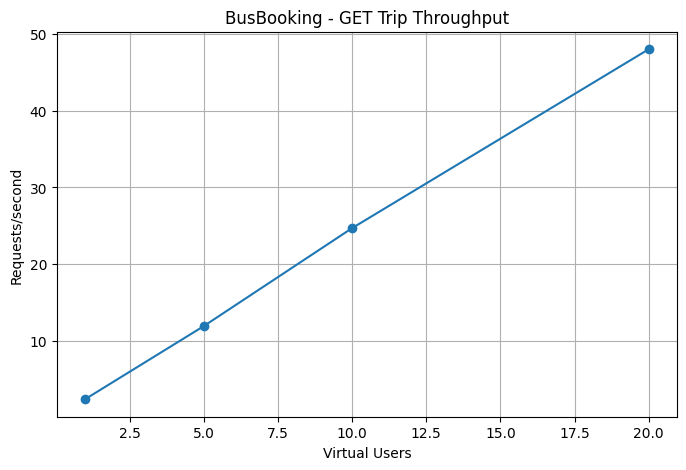

In [19]:
import matplotlib.pyplot as plt

# GET: kết quả từ phần 8
plt.figure(figsize=(8, 5))
plt.plot(summary["users"], summary["rps"], marker="o")
plt.xlabel("Virtual Users")
plt.ylabel("Requests/second")
plt.title("BusBooking - GET Trip Throughput")
plt.grid(True)
plt.savefig(OUTPUT / "get_throughput.png", dpi=160, bbox_inches="tight")
plt.show()

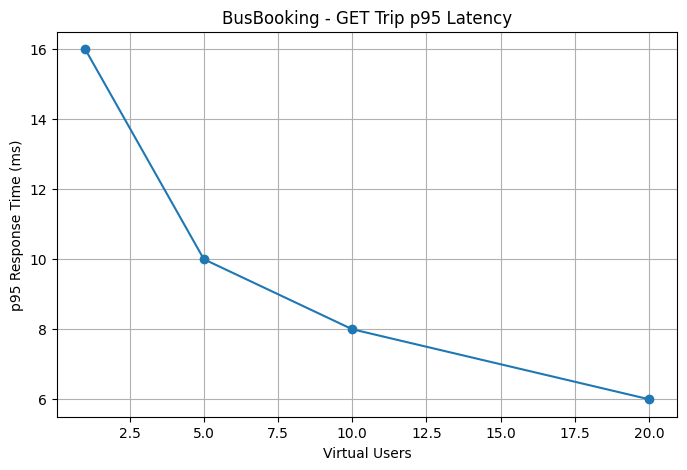

In [20]:
plt.figure(figsize=(8, 5))
plt.plot(summary["users"], summary["p95_ms"], marker="o")
plt.xlabel("Virtual Users")
plt.ylabel("p95 Response Time (ms)")
plt.title("BusBooking - GET Trip p95 Latency")
plt.grid(True)
plt.savefig(OUTPUT / "get_p95_latency.png", dpi=160, bbox_inches="tight")
plt.show()

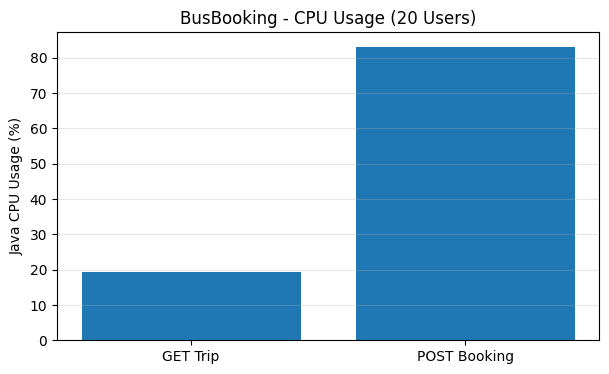

In [21]:
import matplotlib.pyplot as plt

get_cpu = summary.loc[
    summary["users"] == 20, "java_cpu_avg_pct"
].iloc[0]

post_cpu = booking_summary["java_cpu_avg_pct"].iloc[0]

plt.figure(figsize=(7, 4))
plt.bar(["GET Trip", "POST Booking"], [get_cpu, post_cpu])
plt.ylabel("Java CPU Usage (%)")
plt.title("BusBooking - CPU Usage (20 Users)")
plt.grid(axis="y", alpha=0.3)

plt.savefig(OUTPUT / "cpu_comparison.png", dpi=160, bbox_inches="tight")
plt.show()

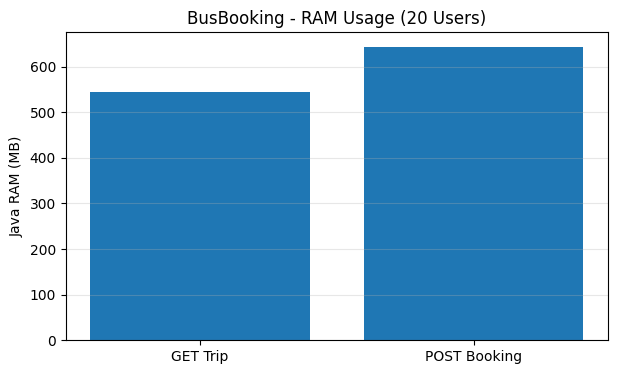

In [22]:
get_ram = summary.loc[
    summary["users"] == 20, "java_rss_max_mb"
].iloc[0]

post_ram = booking_summary["java_ram_max_mb"].iloc[0]

plt.figure(figsize=(7, 4))
plt.bar(["GET Trip", "POST Booking"], [get_ram, post_ram])
plt.ylabel("Java RAM (MB)")
plt.title("BusBooking - RAM Usage (20 Users)")
plt.grid(axis="y", alpha=0.3)

plt.savefig(OUTPUT / "ram_comparison.png", dpi=160, bbox_inches="tight")
plt.show()

# 12 Lưu và xuất báo cáo

In [23]:

# PHẦN 12 — TỔNG KẾT VÀ XUẤT BÁO CÁO PHA 1

from pathlib import Path
from datetime import datetime, timezone
from IPython.display import FileLink, display, Markdown
import pandas as pd
import json
import zipfile
import shutil

OUTPUT = Path("/kaggle/working/busbooking_baseline")
OUTPUT.mkdir(parents=True, exist_ok=True)

# 1. Đọc kết quả benchmark đã lưu
get_path = OUTPUT / "baseline_summary.csv"
post_path = OUTPUT / "booking_summary.csv"

assert get_path.is_file(), "Thiếu kết quả GET ở phần 8"
assert post_path.is_file(), "Thiếu kết quả POST ở phần 10"

get_df = pd.read_csv(get_path)
post_df = pd.read_csv(post_path)

get_20 = get_df.loc[get_df["users"] == 20]
assert not get_20.empty, "Không tìm thấy GET 20 users"

get_20 = get_20.iloc[0]
post_20 = post_df.iloc[-1]

# 2. Kiểm tra dữ liệu
assert int(get_20["failures"]) == 0, "GET có request lỗi"
assert int(post_20["failures"]) == 0, "POST có request lỗi"

assert "inconsistent_count" in globals(), \
    "Chưa chạy kiểm tra ghế ở phần 10.5"

assert inconsistent_count == 0, \
    "Có sai lệch số ghế, chưa nên chốt báo cáo"

# 3. Tạo bảng so sánh GET và POST
comparison = pd.DataFrame([
    {
        "Workload": "GET Trip",
        "Users": 20,
        "Requests": int(get_20["requests"]),
        "RPS": round(float(get_20["rps"]), 2),
        "Average (ms)": round(float(get_20["avg_ms"]), 2),
        "p95 (ms)": round(float(get_20["p95_ms"]), 2),
        "Errors (%)": float(get_20["error_pct"]),
        "Java CPU (%)": round(
            float(get_20["java_cpu_avg_pct"]), 2
        ),
        "Java RAM (MB)": round(
            float(get_20["java_rss_max_mb"]), 2
        ),
    },
    {
        "Workload": "POST Booking",
        "Users": 20,
        "Requests": int(post_20["requests"]),
        "RPS": round(float(post_20["rps"]), 2),
        "Average (ms)": round(float(post_20["avg_ms"]), 2),
        "p95 (ms)": round(float(post_20["p95_ms"]), 2),
        "Errors (%)": float(post_20["error_pct"]),
        "Java CPU (%)": round(
            float(post_20["java_cpu_avg_pct"]), 2
        ),
        "Java RAM (MB)": round(
            float(post_20["java_ram_max_mb"]), 2
        ),
    }
])

comparison.to_csv(
    OUTPUT / "phase1_comparison.csv", index=False
)

# 4. Tạo báo cáo Markdown
timestamp = datetime.now(timezone.utc).strftime(
    "%Y-%m-%d %H:%M UTC"
)

def fmt(row):
    return (
        f"| {row['Workload']} | {row['Users']} | "
        f"{row['Requests']} | {row['RPS']:.2f} | "
        f"{row['Average (ms)']:.2f} | "
        f"{row['p95 (ms)']:.2f} | "
        f"{row['Errors (%)']:.2f}% | "
        f"{row['Java CPU (%)']:.2f}% | "
        f"{row['Java RAM (MB)']:.2f} MB |"
    )

table_lines = "\n".join(
    fmt(row) for _, row in comparison.iterrows()
)

report = f"""# BusBooking — Phase 1 Load Testing Report

**Environment:** Kaggle CPU  
**Generated:** {timestamp}  
**Tools:** Locust, Spring Boot, PostgreSQL

## 1. Test objectives

Establish a performance baseline for Phase 2.

Workloads:
- GET /api/trips and GET /api/trips/{{id}}
- POST /api/bookings

## 2. Test configuration

- GET: 1, 5, 10, 20 virtual users
- POST: 20 virtual users
- Duration: 60 seconds per level
- Spawn rate: up to 5 users/second
- Wait time: 0.2–0.6 seconds
- Load generator and backend share the Kaggle CPU environment
- CPU/RAM statistics measure the Java process only

## 3. Results at 20 virtual users

| Workload | Users | Requests | RPS | Avg ms | p95 ms | Errors | Java CPU | Java RAM |
|---|---:|---:|---:|---:|---:|---:|---:|---:|
{table_lines}

## 4. Database consistency

Trips with incorrect seat balance: **{inconsistent_count}**

No seat balance inconsistency was detected in the
tested POST Booking fixture.

## 5. Interpretation

Both final workloads completed with zero recorded
Locust request failures.

POST Booking includes authentication, transaction
processing and database writes. Its workload is
different from GET Trip, so their results should
not be interpreted as a direct architecture comparison.

These measurements are an initial baseline, not the
maximum capacity of the system.

## 6. Limitations

- All components share the Kaggle CPU environment.
- Measurements are affected by JVM warm-up and caching.
- Workload uses one authenticated test account for POST.
- CPU/RAM exclude PostgreSQL and Locust processes.
- Hardware and fixture must be kept comparable in Phase 2.
- The 60-second measurements include the ramp-up period.
- POST benchmark distributes bookings across many Trips;
  it is not a dedicated last-seat contention test.

## 7. Phase 2 comparison requirements

Use the same:
- CPU environment and recorded hardware configuration
- Database fixture and data volume
- Locust scripts, concurrency, spawn rate and duration
- JVM and PostgreSQL settings, or document differences
- Resource measurement method

Compare RPS, p95 latency, error rate, CPU and RAM.
"""

report_path = OUTPUT / "phase1_load_testing_report.md"
report_path.write_text(report, encoding="utf-8")

# 5. Lưu Locust scripts để nhóm Pha 2 sử dụng
for source, dest in [
    (globals().get("locust_file"),
     "get_trip_locust.py"),
    (globals().get("booking_locust_file"),
     "post_booking_locust.py"),
]:
    if source is not None and Path(source).is_file():
        shutil.copy2(source, OUTPUT / dest)

# 6. Đóng gói báo cáo, CSV, biểu đồ và scripts
zip_path = Path(
    "/kaggle/working/busbooking_phase1_final_report.zip"
)

allowed_names = {
    "baseline_summary.csv",
    "booking_summary.csv",
    "phase1_comparison.csv",
    "phase1_load_testing_report.md",
    "manifest.json",
    "booking_manifest.json",
    "get_trip_locust.py",
    "post_booking_locust.py",
}

report_files = [
    p for p in OUTPUT.iterdir()
    if p.is_file() and (
        p.name in allowed_names
        or (p.suffix == ".png")
        or (
            p.suffix == ".csv"
            and p.name.startswith(("read_u", "booking_u20"))
        )
    )
]

with zipfile.ZipFile(
    zip_path, "w", zipfile.ZIP_DEFLATED
) as zf:
    for file in sorted(report_files):
        zf.write(file, arcname=file.name)

# 7. Hiển thị và cung cấp file tải xuống
print("===== BUSBOOKING PHASE 1 =====")
display(comparison)

print("\nSeat consistency: PASS")
print("Files in ZIP:", len(report_files))
print("Report:", report_path)
print("ZIP:", zip_path)

display(FileLink(str(zip_path)))


===== BUSBOOKING PHASE 1 =====


,Workload,Users,Requests,RPS,Average (ms),p95 (ms),Errors (%),Java CPU (%),Java RAM (MB)
0,GET Trip,20,2834,48.01,5.09,6.0,0.0,19.44,543.86
1,POST Booking,20,2789,47.21,16.09,25.0,0.0,83.02,643.30



Seat consistency: PASS
Files in ZIP: 32
Report: /kaggle/working/busbooking_baseline/phase1_load_testing_report.md
ZIP: /kaggle/working/busbooking_phase1_final_report.zip


/kaggle/working/busbooking_phase1_final_report.zip